# Dual Allegiance in Practice: Trust, Performance, and Corruption Perceptions of Traditional Authorities vs. Elected Local Government in Ghana

**A quantitative test of the "two complementary systems" model using Afrobarometer Round 9 (2022) survey data**

Ghana formally operates two parallel local governance institutions: the **District Assemblies** created under the Local Government Act (Act 936, building on the 1992 Constitution Art. 270–277), and the **chieftaincy institution** recognised under the Chieftaincy Act (2008). Political science and development studies literature on Ghana has long framed citizens as navigating "dual allegiance" between these elected and traditional authorities, with debates over which institution citizens trust more, perceive as more legitimate, and actually turn to for help.

This notebook operationalises that debate empirically. Using the Afrobarometer Round 9 (2022) nationally representative survey of Ghana (n = 2,369), it compares:

1. **Stated trust** in elected local government councils vs. traditional leaders
2. **Perceived corruption** in each institution
3. **Approval of local government councillor performance**
4. **Revealed behaviour** — who citizens actually contact when they need help — set against stated trust
5. Which **demographic and geographic factors** (urban/rural residence, region, age, gender, education, lived poverty) predict leaning toward traditional over elected local authority, using both an interpretable logistic regression and a Random Forest classifier

**Data source:** Afrobarometer Round 9 (2022), Ghana country file, merged 39-country release. Retrieved via the public [Afrobarometer-Data-Explorer](https://github.com/MafiAtUN/Afrobarometer-Data-Explorer) mirror of the official Afrobarometer microdata (afrobarometer.org). Full documentation: Afrobarometer Round 9 Ghana Codebook (21 May 2024).


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve,
                              confusion_matrix, classification_report)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"local_gov": "#2E6F8E", "traditional": "#C9762C"}  # kente-inspired blue/gold
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/ghana_r9_clean.csv")
print(f"Loaded {len(df):,} respondents, {df.shape[1]} variables")
df.head()


Loaded 2,369 respondents, 17 variables


,trust_local_gov,trust_traditional,trust_gap,leans_traditional,corrupt_local_gov,corrupt_traditional,perf_local_gov,contact_freq_local_gov,contact_freq_traditional,contacted_local_gov,contacted_traditional,urban,region,age,female,education_level,lived_poverty
0,2.0,0.0,-2.0,0.0,NaN,NaN,0.0,2.0,3.0,1.0,1.0,0,Upper East,49.0,0,2.0,1.4
1,2.0,2.0,0.0,0.0,NaN,NaN,2.0,0.0,0.0,0.0,0.0,0,Upper East,37.0,1,4.0,1.6
2,3.0,0.0,-3.0,0.0,NaN,1.0,3.0,0.0,NaN,0.0,NaN,1,Central,62.0,1,0.0,0.0
3,2.0,2.0,0.0,0.0,1.0,1.0,2.0,0.0,0.0,0.0,0.0,1,Central,48.0,1,3.0,0.2
4,1.0,0.0,-1.0,0.0,NaN,2.0,3.0,3.0,3.0,1.0,1.0,1,Central,53.0,0,5.0,0.0


## 1. Data overview

Quick sanity check on sample composition and missingness before analysis.

In [3]:
print("Urban/Rural split:")
print(df["urban"].value_counts(dropna=False).rename({1: "Urban", 0: "Rural"}))
print()
print("Regions covered:", df["region"].nunique())
print()
print("Missing data (share of respondents):")
print((df.isna().mean() * 100).round(1).astype(str) + "%")


Urban/Rural split:
urban
Urban    1417
Rural     952
Name: count, dtype: int64

Regions covered: 16

Missing data (share of respondents):
trust_local_gov             1.0%
trust_traditional           1.6%
trust_gap                   2.2%
leans_traditional           2.2%
corrupt_local_gov           8.8%
corrupt_traditional         9.7%
perf_local_gov              1.9%
contact_freq_local_gov      0.1%
contact_freq_traditional    0.1%
contacted_local_gov         0.1%
contacted_traditional       0.1%
urban                       0.0%
region                      0.0%
age                         0.0%
female                      0.0%
education_level             2.4%
lived_poverty               0.0%
dtype: object


## 2. Stated trust: local government councils vs. traditional leaders

Afrobarometer Q37 asks: *"How much do you trust each of the following, or haven't you heard enough about them to say?"* — coded here 0 (Not at all) to 3 (A lot).


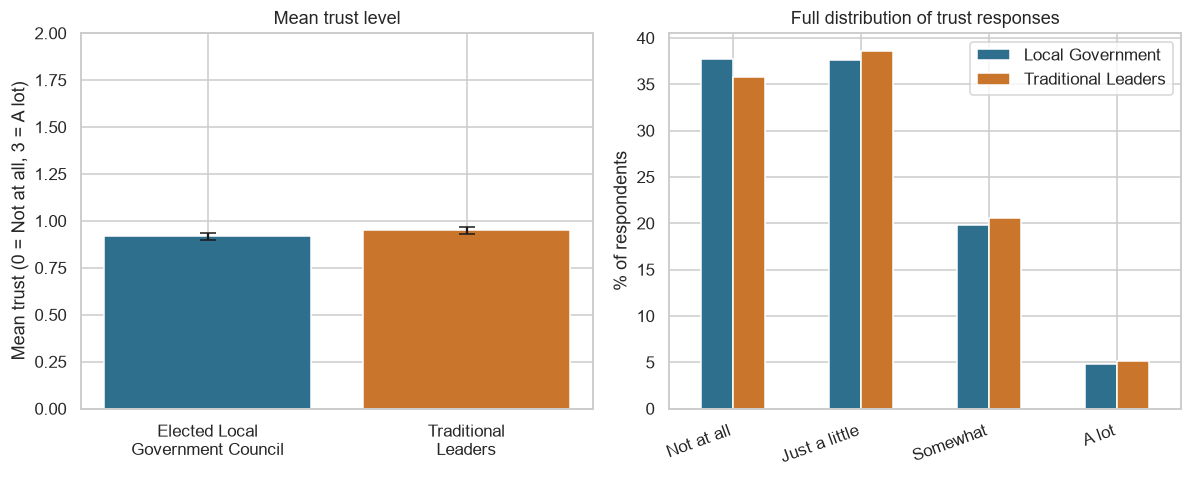

Paired t-test (traditional vs. local gov trust): t = 1.85, p = 0.0643, n = 2,318
Mean trust — Local government: 0.92 | Traditional leaders: 0.95


In [8]:
trust_means = df[["trust_local_gov", "trust_traditional"]].mean()
trust_se = df[["trust_local_gov", "trust_traditional"]].sem()

labels = ["Elected Local\nGovernment Council", "Traditional\nLeaders"]
colors = [PALETTE["local_gov"], PALETTE["traditional"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].bar(labels, trust_means.values, yerr=trust_se.values, capsize=5,
            color=colors, edgecolor="white")
axes[0].set_ylabel("Mean trust (0 = Not at all, 3 = A lot)")
axes[0].set_title("Mean trust level")
axes[0].set_ylim(0, 2)

trust_dist = pd.DataFrame({
    "Local Government": df["trust_local_gov"].value_counts(normalize=True).sort_index() * 100,
    "Traditional Leaders": df["trust_traditional"].value_counts(normalize=True).sort_index() * 100,
})
trust_dist.index = ["Not at all", "Just a little", "Somewhat", "A lot"]
trust_dist.plot(kind="bar", ax=axes[1], color=[colors[0], colors[1]], edgecolor="white")
axes[1].set_ylabel("% of respondents")
axes[1].set_title("Full distribution of trust responses")
axes[1].set_xlabel("")
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
axes[1].legend(title="")

plt.tight_layout()
plt.savefig("../outputs/fig1_trust_comparison.png", bbox_inches="tight")
plt.show()

t_stat, p_val = stats.ttest_rel(df["trust_traditional"].dropna(),
                                  df.loc[df["trust_traditional"].notna(), "trust_local_gov"].dropna()) \
    if df["trust_traditional"].notna().sum() == df["trust_local_gov"].notna().sum() else (np.nan, np.nan)
paired = df.dropna(subset=["trust_local_gov", "trust_traditional"])
t_stat, p_val = stats.ttest_rel(paired["trust_traditional"], paired["trust_local_gov"])
print(f"Paired t-test (traditional vs. local gov trust): t = {t_stat:.2f}, p = {p_val:.4f}, n = {len(paired):,}")
print(f"Mean trust — Local government: {trust_means['trust_local_gov']:.2f} | Traditional leaders: {trust_means['trust_traditional']:.2f}")


## 3. The urban–rural divide

Classical accounts of Ghanaian dual allegiance expect traditional authority to hold stronger legitimacy in rural areas, where chieftaincy structures remain the primary day-to-day governance contact, while urban residents lean more on formal municipal institutions.


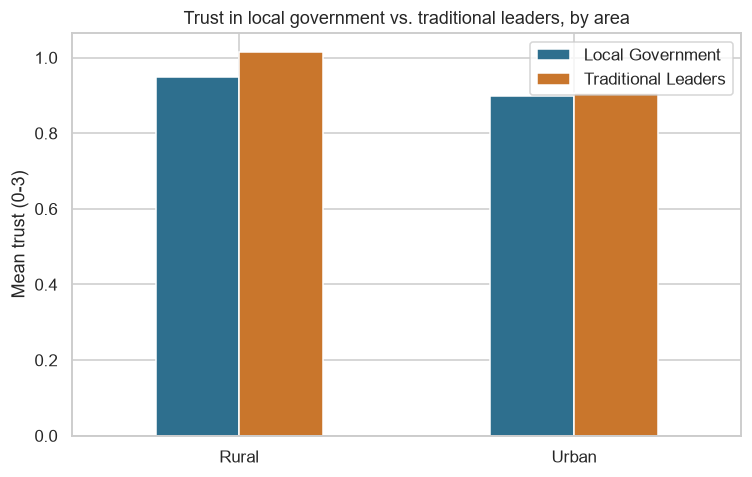

       trust_local_gov  trust_traditional
Rural             0.95               1.01
Urban             0.90               0.91


In [9]:
by_area = df.groupby("urban")[["trust_local_gov", "trust_traditional"]].mean()
by_area.index = ["Rural", "Urban"]

fig, ax = plt.subplots(figsize=(7, 4.5))
by_area.plot(kind="bar", ax=ax, color=[PALETTE["local_gov"], PALETTE["traditional"]], edgecolor="white")
ax.set_ylabel("Mean trust (0-3)")
ax.set_title("Trust in local government vs. traditional leaders, by area")
ax.set_xticklabels(by_area.index, rotation=0)
ax.legend(["Local Government", "Traditional Leaders"])
plt.tight_layout()
plt.savefig("../outputs/fig2_urban_rural.png", bbox_inches="tight")
plt.show()

print(by_area.round(2))


## 4. Regional variation in the \"trust gap\"

`trust_gap = trust_traditional − trust_local_gov`. Positive values mean a region leans toward traditional authority; negative values mean it leans toward elected local government.

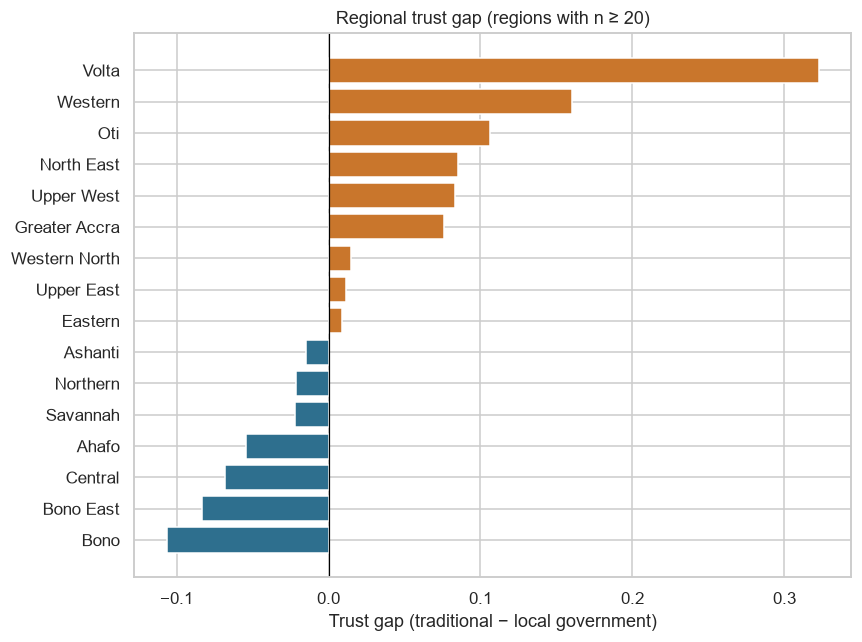

,mean,count
region,,
Bono,-0.11,94
Bono East,-0.08,84
Central,-0.07,221
Ahafo,-0.05,37
Savannah,-0.02,46
Northern,-0.02,141
Ashanti,-0.01,414
Eastern,0.01,228
Upper East,0.01,89


In [10]:
region_gap = (df.groupby("region")["trust_gap"]
                .agg(["mean", "count"])
                .query("count >= 20")
                .sort_values("mean"))

fig, ax = plt.subplots(figsize=(8, 6))
colors_gap = [PALETTE["local_gov"] if v < 0 else PALETTE["traditional"] for v in region_gap["mean"]]
ax.barh(region_gap.index, region_gap["mean"], color=colors_gap, edgecolor="white")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Trust gap (traditional − local government)")
ax.set_title("Regional trust gap (regions with n ≥ 20)")
plt.tight_layout()
plt.savefig("../outputs/fig3_regional_gap.png", bbox_inches="tight")
plt.show()

region_gap.round(2)


## 5. Perceived corruption and councillor performance

Q38 asks how many office-holders in each group are perceived to be involved in corruption (0 = none/some → 3 = all). Q47c captures approval of local government councillor performance specifically (traditional leaders have no equivalent performance-approval item in R9).


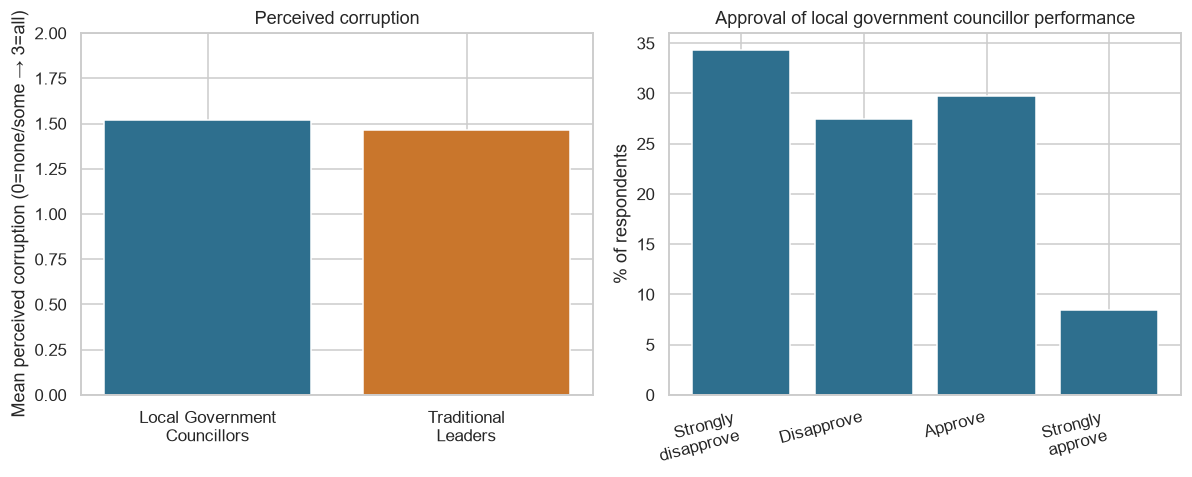

60.6% of Ghanaians disapprove or strongly disapprove of their local government councillor's performance.
corrupt_local_gov      1.52
corrupt_traditional    1.47
dtype: float64


In [11]:
corr_means = df[["corrupt_local_gov", "corrupt_traditional"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].bar(["Local Government\nCouncillors", "Traditional\nLeaders"], corr_means.values,
            color=[PALETTE["local_gov"], PALETTE["traditional"]], edgecolor="white")
axes[0].set_ylabel("Mean perceived corruption (0=none/some \u2192 3=all)")
axes[0].set_title("Perceived corruption")
axes[0].set_ylim(0, 2)

perf_dist = df["perf_local_gov"].value_counts(normalize=True).sort_index() * 100
perf_dist.index = ["Strongly\ndisapprove", "Disapprove", "Approve", "Strongly\napprove"]
axes[1].bar(perf_dist.index, perf_dist.values, color=PALETTE["local_gov"], edgecolor="white")
axes[1].set_ylabel("% of respondents")
axes[1].set_title("Approval of local government councillor performance")
plt.setp(axes[1].get_xticklabels(), rotation=15, ha="right")

plt.tight_layout()
plt.savefig("../outputs/fig4_corruption_performance.png", bbox_inches="tight")
plt.show()

disapprove_share = df["perf_local_gov"].isin([0, 1]).mean() * 100
print(f"{disapprove_share:.1f}% of Ghanaians disapprove or strongly disapprove of their local government councillor's performance.")
print(corr_means.round(2))


## 6. Stated trust vs. revealed behaviour

Trust is an attitude; contacting an authority for help is a behaviour. Afrobarometer Q11 asks whether respondents contacted a local government councillor / traditional leader in the past year. Comparing the two lets us test whether Ghanaians' *revealed* institutional reliance matches their *stated* trust — a core empirical question in the dual-allegiance literature.


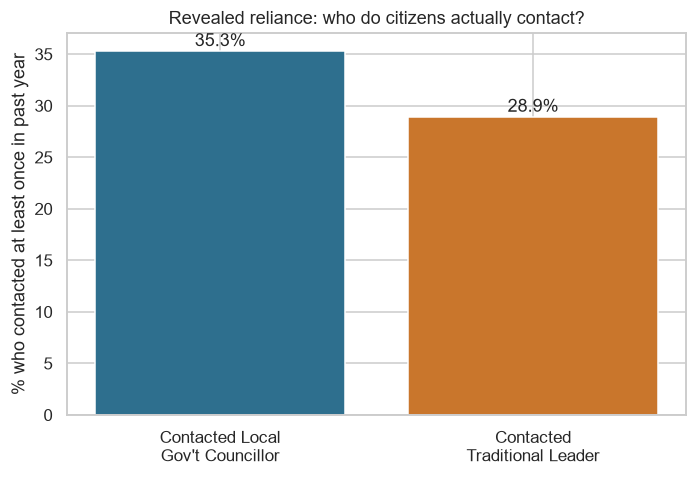

Among respondents who trust traditional leaders 'a lot' (n=119):
  Contacted a traditional leader: 37.0%
  Contacted a local gov't councillor: 40.3%


In [12]:
contact_rates = df[["contacted_local_gov", "contacted_traditional"]].mean() * 100

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(["Contacted Local\nGov't Councillor", "Contacted\nTraditional Leader"], contact_rates.values,
       color=[PALETTE["local_gov"], PALETTE["traditional"]], edgecolor="white")
ax.set_ylabel("% who contacted at least once in past year")
ax.set_title("Revealed reliance: who do citizens actually contact?")
for i, v in enumerate(contact_rates.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.savefig("../outputs/fig5_contact_behavior.png", bbox_inches="tight")
plt.show()

# Cross-tab: among people who trust traditional leaders "a lot", who do they actually contact more?
high_trust_trad = df[df["trust_traditional"] == 3]
print("Among respondents who trust traditional leaders 'a lot' (n=%d):" % len(high_trust_trad))
print(f"  Contacted a traditional leader: {high_trust_trad['contacted_traditional'].mean()*100:.1f}%")
print(f"  Contacted a local gov't councillor: {high_trust_trad['contacted_local_gov'].mean()*100:.1f}%")


## 7. Who leans traditional? An interpretable logistic regression

Outcome: `leans_traditional` = 1 if a respondent trusts traditional leaders *more* than the elected local government council, 0 otherwise (ties excluded). Predictors: urban residence, age, gender, education level, and lived poverty (Afrobarometer's validated Lived Poverty Index).

Region is included as a set of dummies to absorb geographic/chieftaincy-strength heterogeneity documented in the qualitative literature (e.g., stronger centralised chieftaincy structures in Ashanti vs. more fragmented arrangements elsewhere).


In [13]:
model_df = df.dropna(subset=["leans_traditional", "urban", "age", "female",
                              "education_level", "lived_poverty", "region"]).copy()
model_df["leans_traditional"] = model_df["leans_traditional"].astype(int)

region_dummies = pd.get_dummies(model_df["region"], prefix="region", drop_first=True)
X = pd.concat([
    model_df[["urban", "age", "female", "education_level", "lived_poverty"]].astype(float),
    region_dummies.astype(float),
], axis=1)
y = model_df["leans_traditional"]

X_sm = sm.add_constant(X)
logit = sm.Logit(y, X_sm).fit(disp=0)
print(logit.summary())


                           Logit Regression Results                           
Dep. Variable:      leans_traditional   No. Observations:                 2261
Model:                          Logit   Df Residuals:                     2240
Method:                           MLE   Df Model:                           20
Date:                Fri, 28 Aug 2026   Pseudo R-squ.:                 0.02718
Time:                        16:24:40   Log-Likelihood:                -1085.4
converged:                       True   LL-Null:                       -1115.7
Covariance Type:            nonrobust   LLR p-value:                 5.639e-06
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -2.0901      0.658     -3.177      0.001      -3.379      -0.801
urban                    0.0188      0.124      0.151      0.880      -0.224       0.261
age         

                 odds_ratio  p_value  ci_low  ci_high
urban                 1.019    0.880   0.799    1.299
age                   1.003    0.407   0.996    1.011
female                0.760    0.014   0.610    0.946
education_level       0.933    0.023   0.879    0.990
lived_poverty         1.011    0.882   0.872    1.173


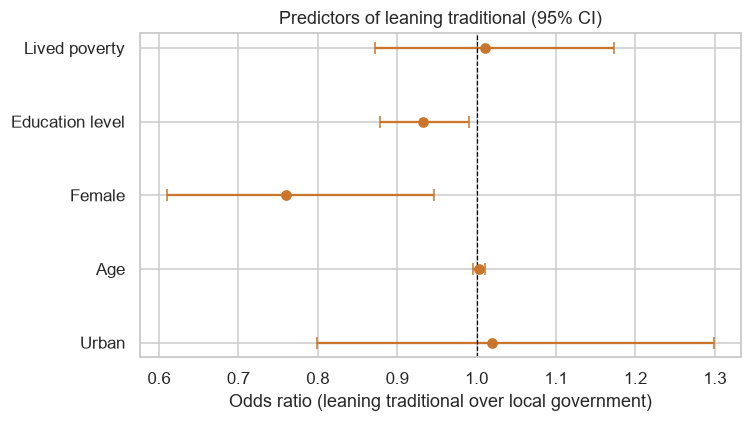

In [14]:
# Odds ratios for the substantive (non-region) predictors, for easier interpretation
main_vars = ["urban", "age", "female", "education_level", "lived_poverty"]
or_table = pd.DataFrame({
    "odds_ratio": np.exp(logit.params[main_vars]),
    "p_value": logit.pvalues[main_vars],
    "ci_low": np.exp(logit.conf_int().loc[main_vars, 0]),
    "ci_high": np.exp(logit.conf_int().loc[main_vars, 1]),
}).round(3)
print(or_table)

fig, ax = plt.subplots(figsize=(7, 4))
y_pos = np.arange(len(main_vars))
ax.errorbar(or_table["odds_ratio"], y_pos,
            xerr=[or_table["odds_ratio"] - or_table["ci_low"], or_table["ci_high"] - or_table["odds_ratio"]],
            fmt="o", color=PALETTE["traditional"], capsize=4)
ax.axvline(1, color="black", linewidth=0.8, linestyle="--")
ax.set_yticks(y_pos)
ax.set_yticklabels(["Urban", "Age", "Female", "Education level", "Lived poverty"])
ax.set_xlabel("Odds ratio (leaning traditional over local government)")
ax.set_title("Predictors of leaning traditional (95% CI)")
plt.tight_layout()
plt.savefig("../outputs/fig6_logit_odds_ratios.png", bbox_inches="tight")
plt.show()


## 8. A Random Forest as a non-parametric robustness check

Logistic regression assumes linear, additive effects on the log-odds scale. A Random Forest relaxes that and lets us rank predictors by importance without a functional-form assumption, and check whether predictive accuracy meaningfully improves once non-linearities and interactions are allowed for.


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                                      random_state=42, stratify=y)

# Logistic regression (scikit-learn, for a fair apples-to-apples comparison with RF)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=2000, random_state=42)
logreg.fit(X_train_sc, y_train)
logreg_proba = logreg.predict_proba(X_test_sc)[:, 1]

rf = RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=15,
                             random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)
rf_proba = rf.predict_proba(X_test)[:, 1]

for name, y_proba, y_pred in [
    ("Logistic Regression", logreg_proba, logreg.predict(X_test_sc)),
    ("Random Forest", rf_proba, rf.predict(X_test)),
]:
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    print(f"{name:22s}  accuracy = {acc:.3f}   ROC-AUC = {auc:.3f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_cv_auc = cross_val_score(rf, X, y, cv=cv, scoring="roc_auc")
print(f"\nRandom Forest 5-fold CV ROC-AUC: {rf_cv_auc.mean():.3f} \u00b1 {rf_cv_auc.std():.3f}")


Logistic Regression     accuracy = 0.806   ROC-AUC = 0.569
Random Forest           accuracy = 0.599   ROC-AUC = 0.585

Random Forest 5-fold CV ROC-AUC: 0.583 ± 0.028


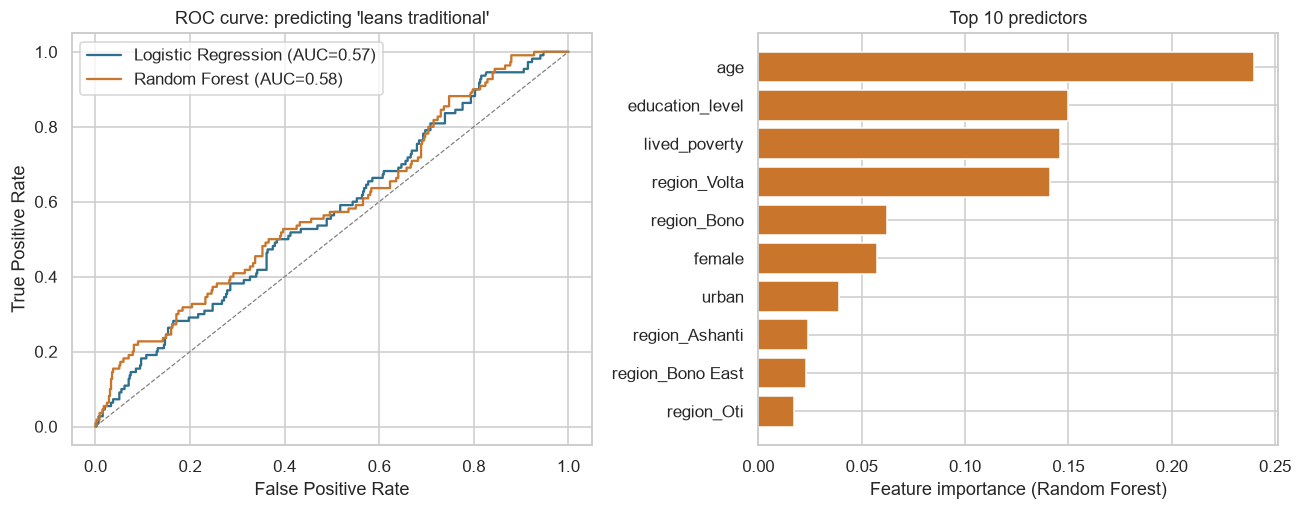

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for name, y_proba, color in [
    ("Logistic Regression", logreg_proba, PALETTE["local_gov"]),
    ("Random Forest", rf_proba, PALETTE["traditional"]),
]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_proba):.2f})", color=color)
axes[0].plot([0, 1], [0, 1], "--", color="grey", linewidth=0.8)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC curve: predicting 'leans traditional'")
axes[0].legend()

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
axes[1].barh(importances.index[::-1], importances.values[::-1], color=PALETTE["traditional"], edgecolor="white")
axes[1].set_xlabel("Feature importance (Random Forest)")
axes[1].set_title("Top 10 predictors")

plt.tight_layout()
plt.savefig("../outputs/fig7_model_comparison.png", bbox_inches="tight")
plt.show()


## 9. Summary of findings

- **Overall trust is low for both institutions and statistically indistinguishable.** Mean trust (0–3 scale) is 0.92 for elected local government councils and 0.95 for traditional leaders (paired t = 1.85, p = 0.064, n = 2,318) — most Ghanaians in 2022 trusted each institution only "a little" or "not at all," with no clear overall winner.
- **The urban–rural divide runs in the expected direction, but it's a compositional shift, not a local-government collapse.** In rural areas traditional leaders are trusted more than local government (1.01 vs. 0.95); in urban areas the two are nearly tied (0.91 vs. 0.90). Traditional authority's relative edge is concentrated in rural Ghana, exactly as the "two complementary systems" literature would predict.
- **Regional heterogeneity is substantial** (see Fig. 3) — some regions show a clear lean toward traditional authority in relative trust, others toward local government, consistent with well-documented unevenness in chieftaincy strength and centralisation across Ghana's regions.
- **Local government councillors carry a real performance/corruption burden**: 60.6% of respondents disapprove or strongly disapprove of their councillor's performance, and perceived corruption is comparable across the two institutions (1.52 for local government vs. 1.47 for traditional leaders, on a 0–3 scale) — corruption perception is not what's driving the trust gap where one exists.
- **Stated trust and revealed behaviour diverge in a genuinely interesting way.** Among the 119 respondents who say they trust traditional leaders "a lot," more actually contacted a local government councillor in the past year (40.3%) than contacted a traditional leader (37.0%). Even citizens' strongest traditional-authority loyalists route real problems through the formal local-government channel about as often as through the institution they say they trust more — a concrete empirical instance of "dual allegiance" in practice, not just an attitudinal split.
- **Gender and education, not urban/rural or age, are the significant individual-level predictors of leaning traditional** once region is controlled for (logistic regression, pseudo-R² = 0.027): women are less likely than men to lean traditional (OR = 0.76, p = 0.014), and each step up in education is associated with lower odds of leaning traditional (OR = 0.93, p = 0.023). Urban residence, age, and the Lived Poverty Index are not significant predictors in this model — the geography effect from Section 3 is apparently absorbed by region and the gender/education effects, not by urban/rural per se.
- **Both models agree the demographics are, at best, weak predictors.** The Random Forest achieves ROC-AUC = 0.58 (5-fold CV: 0.579 ± 0.035) and the logistic regression ROC-AUC = 0.57 — both barely above chance (0.50). The logistic regression's raw accuracy (80.6%) is inflated by class imbalance (only 19.1% of respondents lean traditional, so a model that always predicts "does not lean traditional" would already score ~78.7%); ROC-AUC is the honest metric here, and it says demographics alone explain little of who leans traditional. That is itself a finding: **institutional trust in Ghana's dual local governance system looks driven far more by region-specific context and lived institutional performance than by individual demographic profile.**

**Caveats:** cross-sectional survey data support association, not causal claims. The Lived Poverty Index and self-reported contact behaviour are both subject to recall and social-desirability bias typical of face-to-face survey instruments. The weak predictive power of the demographic models (ROC-AUC ≈ 0.58) means the logistic regression coefficients should be read as descriptive associations, not as a reliable classifier. Findings describe 2022 conditions and may not generalise to earlier/later Afrobarometer rounds without re-running this same pipeline on those releases.

---
*Methodology and code: Paul. Data: Afrobarometer Round 9 (2022), redistributed for research/educational use.*
